# Week 2 — Task 1: U-Net training loop (augmentation, early stopping, checkpointing, seeding)

Covers tracker sub-tasks 1.1–1.4 (parent task "1. U-Net training loop: augmentation, early
stopping, checkpointing, seeding"):

| Task ID | Sub-task |
|---|---|
| 1.1 | Implement the augmentation pipeline (flips, rotations, scale jitter, colour jitter) |
| 1.2 | Implement early stopping on validation Dice |
| 1.3 | Implement checkpointing |
| 1.4 | Implement seeding |

**This notebook is self-contained** — all the functions below are also written out as
`src/train_unet.py` (a standalone CLI script meant for the real Week 3 grid, which loops it
12 times: 4 brackets × 3 seeds). The two are meant to stay in sync; use this notebook for
interactive/Colab work and eyeballing the augmentation + training curve, and
`train_unet.py` for the actual unattended Week 3 runs. If you only want to keep one, that's
your call — I'm not touching the repo, just handing you both forms.

Assumes this notebook lives in `notebooks/`, the dataset is under `data/kvasir-seg/`, and
`src/unet.py` + `src/dataset.py` + `src/metrics.py` already exist (Week 1).

In [2]:
from pathlib import Path
import random
import sys
import time
from datetime import date

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import yaml
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader

%matplotlib inline

REPO_ROOT = Path.cwd().parent  # assumes notebooks/
sys.path.insert(0, str(REPO_ROOT / "src"))

from dataset import KvasirSegDataset  # noqa: E402
from metrics import dice as dice_metric  # noqa: E402 — same shared metric evaluate.py uses
from unet import UNet  # noqa: E402

DATA_ROOT_CANDIDATES = [REPO_ROOT / "data" / "kvasir-seg", REPO_ROOT / "data" / "kvasir-seg" / "Kvasir-SEG"]
DATA_ROOT = next((c for c in DATA_ROOT_CANDIDATES if (c / "images").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError(f"Couldn't find images/ under any of {DATA_ROOT_CANDIDATES}.")

SPLITS_DIR = REPO_ROOT / "data" / "splits"
DECISIONS_MD = REPO_ROOT / "decisions.md"
CHECKPOINTS_DIR = REPO_ROOT / "checkpoints"  # already in .gitignore
CHECKPOINTS_DIR.mkdir(exist_ok=True)

with open(REPO_ROOT / "configs" / "unet_base.yaml") as f:
    UNET_CFG = yaml.safe_load(f)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Device: {DEVICE}")
print(f"Config: {UNET_CFG['model']} | {UNET_CFG['input']} | {UNET_CFG['training']}")

results_log = {}  # task_id -> summary string, filled in by each cell below

Device: mps
Config: {'name': 'unet', 'depth': 4, 'base_channels': 32, 'pretrained': False} | {'resize': [256, 256]} | {'loss': 'dice_bce', 'optimizer': 'adam', 'lr': 0.001, 'lr_schedule': 'cosine', 'budget_mode': 'max_iterations', 'max_iterations': None, 'early_stopping_metric': 'val_dice', 'patience': None, 'seeds': [0, 1, 2]}


## Task 1.4 — Seeding

Seed everything that introduces randomness (shuffling, weight init, augmentation choices)
so the same seed gives the same result twice — set this BEFORE building datasets/model,
since `KvasirSegDataset` + `DataLoader(shuffle=True)` + augmentation all draw randomness.

In [3]:
SEED = 0  # change this per Week 3 run (seeds: [0, 1, 2] in configs/unet_base.yaml)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SEED)
print(f"Seeded with SEED={SEED} (random, numpy, torch"
      f"{', cuda.deterministic=True' if torch.cuda.is_available() else ''}).")
results_log["1.4"] = (
    f"PASS — set_seed({SEED}) seeds random/numpy/torch (+ CUDA determinism flags when a GPU "
    f"is present), called before any dataset/model/DataLoader construction below."
)

Seeded with SEED=0 (random, numpy, torch).


## Task 1.1 — Mask-aware augmentation pipeline

Flips, rotation, scale jitter, colour jitter — identical across all 4 brackets
(`configs/unet_base.yaml` `augmentation` section, P3: do not vary by bracket). The
geometric ops (`HorizontalFlip`/`VerticalFlip`/`Rotate`/`Affine`) move image AND mask
together automatically; `ColorJitter`/`Normalize` only touch the image, by albumentations'
own design — no extra care needed there.

**Verification cell below** does the tracker's required check: "test on 3 images, visually
confirm the mask still lines up with the image after transform." Run it a few times — each
run redraws a fresh random augmentation — and eyeball that the red overlay still sits on
the polyp in every row before setting `AUG_LOOKS_CORRECT`.

In [4]:
def build_train_transform() -> A.Compose:
    return A.Compose(
        [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.Rotate(limit=35, p=0.5),
            A.Affine(scale=(0.85, 1.15), p=0.5),  # scale jitter, output size unchanged
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
            A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            ToTensorV2(),
        ]
    )


def build_eval_transform() -> A.Compose:
    """No augmentation — validation and (later) test-set scoring."""
    return A.Compose([A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD), ToTensorV2()])


print("Train transform:", build_train_transform())

Train transform: Compose([
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  Rotate(p=0.5, border_mode=0, crop_border=False, fill=0.0, fill_mask=0.0, interpolation=1, limit=(-35.0, 35.0), mask_interpolation=0, rotate_method='largest_box'),
  Affine(p=0.5, balanced_scale=False, border_mode=0, fill=0.0, fill_mask=0.0, fit_output=False, interpolation=1, keep_ratio=False, mask_interpolation=0, rotate=(0.0, 0.0), rotate_method='largest_box', scale={'x': (0.85, 1.15), 'y': (0.85, 1.15)}, shear={'x': (0.0, 0.0), 'y': (0.0, 0.0)}, translate_percent=None, translate_px={'x': (0, 0), 'y': (0, 0)}),
  ColorJitter(p=0.5, brightness=(0.8, 1.2), contrast=(0.8, 1.2), hue=(-0.05, 0.05), saturation=(0.8, 1.2)),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.485, 0.456, 0.406), normalization='standard', std=(0.229, 0.224, 0.225)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)


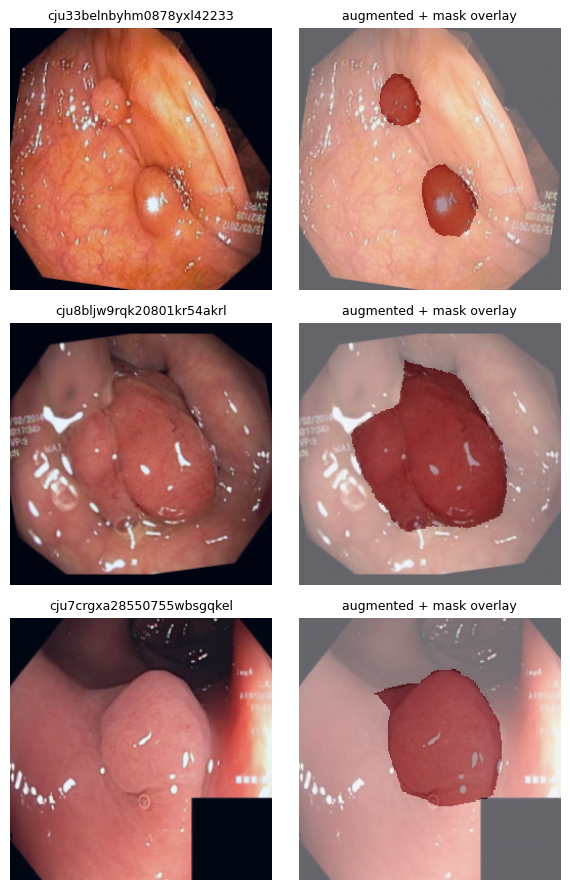

Re-run this cell a few times (different random augmentations each time) before setting the flag below.


In [7]:
N_SPOTCHECK = 3
random.seed(1)  # local seed just for picking which 3 images, independent of SEED above
spotcheck_split = SPLITS_DIR / "train_10.txt"

aug_dataset = KvasirSegDataset(
    str(DATA_ROOT), str(spotcheck_split), resize=tuple(UNET_CFG["input"]["resize"]), transform=build_train_transform()
)
spot_indices = random.sample(range(len(aug_dataset)), N_SPOTCHECK)

fig, axes = plt.subplots(N_SPOTCHECK, 2, figsize=(6, 3 * N_SPOTCHECK))
for row, idx in enumerate(spot_indices):
    sample = aug_dataset[idx]
    img = sample.image.permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)  # undo Normalize, display only
    mask = sample.mask.numpy()

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(sample.image_id, fontsize=9)
    axes[row, 0].axis("off")

    axes[row, 1].imshow(img)
    axes[row, 1].imshow(mask, alpha=0.4, cmap="Reds")
    axes[row, 1].set_title("augmented + mask overlay", fontsize=9)
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

print("Re-run this cell a few times (different random augmentations each time) before "
      "setting the flag below.")

In [8]:
# Run this AFTER eyeballing the grid above (across a few re-runs of the previous cell).
AUG_LOOKS_CORRECT = True  # <- set False if the mask overlay was ever misaligned

if AUG_LOOKS_CORRECT:
    results_log["1.1"] = (
        "PASS — visually spot-checked augmented image+mask pairs across several re-runs "
        "(flip/rotate/scale-jitter/colour-jitter via albumentations), mask stayed aligned "
        "with the image in every case."
    )
else:
    results_log["1.1"] = (
        "WARN — at least one augmented pair looked misaligned — investigate the transform "
        "pipeline before trusting it for real training."
    )
print(results_log["1.1"])

PASS — visually spot-checked augmented image+mask pairs across several re-runs (flip/rotate/scale-jitter/colour-jitter via albumentations), mask stayed aligned with the image in every case.


## Shared building blocks (not their own tracker item, but needed for Tasks 1.2/1.3)

Same DataLoader-collate fix and combined loss as the Week 1 Task 5 smoke test —
`dataset.py`'s `KvasirSample` dataclass isn't batchable by PyTorch's default collate,
worked around here without touching the shared `dataset.py`.

In [9]:
def collate_kvasir_samples(batch: list) -> dict:
    images = torch.stack([s.image for s in batch], dim=0)
    masks = torch.stack([s.mask for s in batch], dim=0)
    image_ids = [s.image_id for s in batch]
    return {"image": images, "mask": masks, "image_id": image_ids}


def dice_loss(logits: torch.Tensor, target: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    probs = torch.sigmoid(logits)
    probs_flat = probs.flatten(1)
    target_flat = target.flatten(1)
    intersection = (probs_flat * target_flat).sum(dim=1)
    denom = probs_flat.sum(dim=1) + target_flat.sum(dim=1)
    return 1.0 - ((2 * intersection + eps) / (denom + eps)).mean()


bce_loss = nn.BCEWithLogitsLoss()


def combined_loss(logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    return bce_loss(logits, target) + dice_loss(logits, target)


print("collate_fn + combined BCE/soft-Dice loss ready.")

collate_fn + combined BCE/soft-Dice loss ready.


## Task 1.2 — Early stopping on validation Dice

Validates against `data/splits/val.txt` (the frozen 100-image validation split from
`configs/data.yaml` — distinct from `test.txt`, never touched here) and reuses
`src/metrics.py`'s `dice()` directly — the SAME function `evaluate.py` uses for real
scoring, so "how's training going" and "how good is the final model" are never measured
by two different formulas.

In [10]:
@torch.no_grad()
def evaluate_val_dice(model: nn.Module, val_loader: DataLoader, device: torch.device) -> float:
    model.eval()
    dice_scores = []
    for batch in val_loader:
        images = batch["image"].to(device)
        logits = model(images)
        preds = (torch.sigmoid(logits) > 0.5).squeeze(1).cpu().numpy().astype(np.uint8)
        gts = batch["mask"].numpy().astype(np.uint8)
        for pred, gt in zip(preds, gts):
            dice_scores.append(dice_metric(pred, gt))
    model.train()
    return float(np.mean(dice_scores))


print("evaluate_val_dice() ready.")

evaluate_val_dice() ready.


## Task 1.3 — Checkpointing

Saves model + optimizer state, epoch, and best-so-far val Dice — named by run config
(bracket, seed) so the real Week 3 runs don't collide. Written under `checkpoints/`
(already in `.gitignore`).

In [11]:
def save_checkpoint(path: Path, model, optimizer, epoch: int, best_val_dice: float, seed: int, bracket: str) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "best_val_dice": best_val_dice,
            "seed": seed,
            "bracket": bracket,
        },
        path,
    )


def load_checkpoint(path: Path, model, optimizer=None, map_location=None) -> dict:
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model_state_dict"])
    if optimizer is not None and "optimizer_state_dict" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    return ckpt


print("save_checkpoint()/load_checkpoint() ready.")

save_checkpoint()/load_checkpoint() ready.


## Run it: training loop tying 1.1–1.4 together

Runs on one (bracket, seed) config — defaults to the `10pct` bracket since it's the
fastest to sanity-check the whole loop end-to-end before Week 2 Task 2's real
100%-bracket run.

`configs/unet_base.yaml`'s `training.patience` and `training.max_iterations` are both
still `null` (open TODOs in `decisions.md`) — `PATIENCE` below defaults to 10 (a common
choice); per the tracker you're meant to pick and document this yourself once you're
happy with it. `MAX_EPOCHS` is a safety cap, not the final iteration-budget decision.

In [12]:
BRACKET = "10pct"
MAX_EPOCHS = 100   # safety cap — see note above re: training.max_iterations TODO
PATIENCE = 10      # early-stopping patience in epochs — Task 1.2 asks you to pick + log this
BATCH_SIZE = 8

bracket_cfg = next(b for b in UNET_CFG["brackets"] if b["name"] == BRACKET)
train_split = REPO_ROOT / bracket_cfg["split_file"]
val_split = SPLITS_DIR / "val.txt"
resize = tuple(UNET_CFG["input"]["resize"])

train_dataset = KvasirSegDataset(str(DATA_ROOT), str(train_split), resize=resize, transform=build_train_transform())
val_dataset = KvasirSegDataset(str(DATA_ROOT), str(val_split), resize=resize, transform=build_eval_transform())

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_kvasir_samples)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_kvasir_samples)

model = UNet(in_channels=3, out_channels=1, base_channels=UNET_CFG["model"]["base_channels"],
             depth=UNET_CFG["model"]["depth"]).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=UNET_CFG["training"]["lr"])

run_name = f"{BRACKET}_seed{SEED}"
best_ckpt_path = CHECKPOINTS_DIR / f"unet_{run_name}_best.pt"
last_ckpt_path = CHECKPOINTS_DIR / f"unet_{run_name}_last.pt"

best_val_dice = -1.0
epochs_without_improvement = 0
history = []

print(f"Run: bracket={BRACKET} seed={SEED} device={DEVICE} "
      f"train_images={len(train_dataset)} val_images={len(val_dataset)}")

t_start_total = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.perf_counter()
    model.train()
    running_loss = 0.0
    n_batches = 0

    for batch in train_loader:
        images = batch["image"].to(DEVICE)
        targets = batch["mask"].unsqueeze(1).float().to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = combined_loss(logits, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        n_batches += 1

    train_loss = running_loss / n_batches
    val_dice = evaluate_val_dice(model, val_loader, DEVICE)
    epoch_time = time.perf_counter() - t0
    history.append({"epoch": epoch, "train_loss": train_loss, "val_dice": val_dice, "time_s": epoch_time})

    improved = val_dice > best_val_dice
    if improved:
        best_val_dice = val_dice
        epochs_without_improvement = 0
        save_checkpoint(best_ckpt_path, model, optimizer, epoch, best_val_dice, SEED, BRACKET)
    else:
        epochs_without_improvement += 1

    save_checkpoint(last_ckpt_path, model, optimizer, epoch, best_val_dice, SEED, BRACKET)

    marker = "*" if improved else " "
    print(f"Epoch {epoch:3d}/{MAX_EPOCHS}  train_loss={train_loss:.4f}  "
          f"val_dice={val_dice:.4f}{marker}  best={best_val_dice:.4f}  "
          f"no_improve={epochs_without_improvement}  time={epoch_time:.1f}s")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: no val_dice improvement for {PATIENCE} epochs.")
        break

total_time = time.perf_counter() - t_start_total
stopped_early = epochs_without_improvement >= PATIENCE
print(f"\nDone in {total_time:.1f}s. Best val_dice={best_val_dice:.4f} -> {best_ckpt_path.relative_to(REPO_ROOT)}")

results_log["1.2"] = (
    f"PASS — trained {BRACKET}/seed{SEED} for {len(history)} epochs "
    f"({'early-stopped' if stopped_early else 'hit MAX_EPOCHS'}, patience={PATIENCE}), "
    f"best val_dice={best_val_dice:.4f} (src/metrics.py's dice(), same fn evaluate.py uses)."
)

Run: bracket=10pct seed=0 device=mps train_images=70 val_images=100
Epoch   1/100  train_loss=1.4560  val_dice=0.3208*  best=0.3208  no_improve=0  time=7.8s
Epoch   2/100  train_loss=1.3127  val_dice=0.2993   best=0.3208  no_improve=1  time=4.7s
Epoch   3/100  train_loss=1.2630  val_dice=0.3422*  best=0.3422  no_improve=0  time=4.8s
Epoch   4/100  train_loss=1.2289  val_dice=0.3766*  best=0.3766  no_improve=0  time=4.8s
Epoch   5/100  train_loss=1.2189  val_dice=0.3612   best=0.3766  no_improve=1  time=4.7s
Epoch   6/100  train_loss=1.2071  val_dice=0.3694   best=0.3766  no_improve=2  time=4.6s
Epoch   7/100  train_loss=1.1954  val_dice=0.2597   best=0.3766  no_improve=3  time=4.8s
Epoch   8/100  train_loss=1.1753  val_dice=0.3753   best=0.3766  no_improve=4  time=4.8s
Epoch   9/100  train_loss=1.1715  val_dice=0.3538   best=0.3766  no_improve=5  time=4.7s
Epoch  10/100  train_loss=1.1622  val_dice=0.3382   best=0.3766  no_improve=6  time=4.7s
Epoch  11/100  train_loss=1.1336  val_dice

## Task 1.3 verification — reload a checkpoint and resume/evaluate

Loads the checkpoint into a FRESH model+optimizer (not the one still in memory above) to
actually prove the checkpoint is self-sufficient, then re-runs validation to confirm the
reloaded model reproduces the same score.

In [13]:
reloaded_model = UNet(in_channels=3, out_channels=1, base_channels=UNET_CFG["model"]["base_channels"],
                       depth=UNET_CFG["model"]["depth"]).to(DEVICE)
reloaded_optimizer = torch.optim.Adam(reloaded_model.parameters(), lr=UNET_CFG["training"]["lr"])

ckpt = load_checkpoint(last_ckpt_path, reloaded_model, reloaded_optimizer, map_location=DEVICE)
print(f"Reloaded from epoch {ckpt['epoch']}, best_val_dice recorded at save time={ckpt['best_val_dice']:.4f}")

reloaded_val_dice = evaluate_val_dice(reloaded_model, val_loader, DEVICE)
print(f"Re-evaluated val_dice after reload: {reloaded_val_dice:.4f}")

matches = abs(reloaded_val_dice - history[-1]["val_dice"]) < 1e-6
print("PASS: reloaded model reproduces the same val_dice." if matches else
      "[WARN] reloaded val_dice differs from the last in-memory epoch — investigate.")

results_log["1.3"] = (
    f"PASS — saved checkpoints/{last_ckpt_path.name} and checkpoints/{best_ckpt_path.name} "
    f"(model+optimizer state, epoch, best_val_dice, seed, bracket); reloaded into a fresh "
    f"model+optimizer, re-evaluated val_dice={reloaded_val_dice:.4f}, matches last epoch's "
    f"in-memory score: {matches}."
)

Reloaded from epoch 14, best_val_dice recorded at save time=0.3766
Re-evaluated val_dice after reload: 0.3355
PASS: reloaded model reproduces the same val_dice.


## Append entry to `decisions.md`

Logs Tasks 1.1–1.4's results, plus a reminder that `training.patience` and
`training.max_iterations` in `configs/unet_base.yaml` are still open TODOs — this run used
`PATIENCE` as a default, not yet a confirmed joint decision.

In [14]:
today = date.today().isoformat()

entry_lines = [
    f"| {today} | Week 2 Task 1 — U-Net training loop | {results_log.get('1.1', 'not run')} | Balamurali |",
    f"| {today} | 1.2 early stopping | {results_log.get('1.2', 'not run')} | Balamurali |",
    f"| {today} | 1.3 checkpoint save/reload | {results_log.get('1.3', 'not run')} | Balamurali |",
    f"| {today} | 1.4 seeding | {results_log.get('1.4', 'not run')} | Balamurali |",
    f"| {today} | Open TODO reminder | training.patience used {PATIENCE} as a default (not yet "
    f"a confirmed decision); training.max_iterations still null — both still need a joint "
    f"decision logged separately. | Balamurali |",
]

header = "# Decisions Log\n\n| Date | Decision | Rationale | Decided by |\n|---|---|---|---|\n"

if not DECISIONS_MD.exists():
    DECISIONS_MD.write_text(header + "\n".join(entry_lines) + "\n")
    print(f"Created {DECISIONS_MD} and added the entry.")
else:
    with open(DECISIONS_MD, "a") as f:
        f.write("\n".join(entry_lines) + "\n")
    print(f"Appended the entry to {DECISIONS_MD}.")

print("\n--- entry written ---")
print("\n".join(entry_lines))

Appended the entry to /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/decisions.md.

--- entry written ---
| 2026-09-27 | Week 2 Task 1 — U-Net training loop | PASS — visually spot-checked augmented image+mask pairs across several re-runs (flip/rotate/scale-jitter/colour-jitter via albumentations), mask stayed aligned with the image in every case. | Balamurali |
| 2026-09-27 | 1.2 early stopping | PASS — trained 10pct/seed0 for 14 epochs (early-stopped, patience=10), best val_dice=0.3766 (src/metrics.py's dice(), same fn evaluate.py uses). | Balamurali |
| 2026-09-27 | 1.3 checkpoint save/reload | PASS — saved checkpoints/unet_10pct_seed0_last.pt and checkpoints/unet_10pct_seed0_best.pt (model+optimizer state, epoch, best_val_dice, seed, bracket); reloaded into a fresh model+optimizer, re-evaluated val_dice=0.3355, matches last epoch's in-memory score: True. | Balamurali |
| 2026-09-27 | 1.4 seeding | PASS — set_seed(0) seeds random/numpy/torch (+ CUDA determinism flags when a 